# PYRAXIS: training the fire-safety models

This notebook trains every model behind the dashboard, layer by layer:

| Layer | Question | Data (PSI investigations) | Model |
|---|---|---|---|
| **Prevention** | Will this solid keep burning once lit? | BASS (crew observations, as-run matrix) | GP classifier |
| **Detection** | How much smoke, how big are the particles, which detector sees it? | SAME, SAME-R (instrument logs), SPICE (smoke points) | GP regression |
| **Suppression** | Does this atmosphere put the flame out, and does it stay out? | FLEX + CFI droplet tests | GP regression + GP classifiers |

The heavy lifting lives in `pipeline/train_models.py` (and the dataset builders `pipeline/build_*.py`). This notebook imports those functions, so the notebook and the scripts always give the same numbers.

**Kernel:** `Python (spaceapp)`. Run top to bottom (*Run All*). The suppression cross-validation takes about 3–4 minutes.

## 1. Setup

In [1]:
import sys, json, pathlib, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

# find the project root (folder that contains pipeline/)
ROOT = pathlib.Path.cwd()
while not (ROOT / "pipeline").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "pipeline"))
P = ROOT / "data/processed"
print("project root:", ROOT)

# ---- settings ----
REBUILD_DATA = False   # True = re-read raw PSI files from data/raw (D: drive must be connected; ~10 min)
SAVE_OUTPUTS = True    # True = write model files + dashboard JSON at the end
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

project root: C:\Users\USER\Desktop\Projects\nasa


## 2. (Optional) rebuild the datasets from raw PSI files

Skip this unless the raw data changed. It runs the three dataset builders:
- `build_tests.py`: one row per test from every *Experimental table*, plus the CFI data summary and the BASS as-run matrix
- `build_detection.py`: one row per SAME/SAME-R smoke test from the 1 Hz instrument logs
- `build_smoke_points.py`: SPICE smoke-point flames

In [2]:
if REBUILD_DATA:
    import build_tests, build_detection, build_smoke_points
    build_tests.main(); build_detection.main(); build_smoke_points.main()
else:
    print("using existing files in data/processed/")

using existing files in data/processed/


## 3. The datasets

In [3]:
tests = pd.read_parquet(P / "tests.parquet")
det = pd.read_parquet(P / "detection.parquet")
sp = pd.read_parquet(P / "smoke_points.parquet")

overview = pd.DataFrame([
    ["Prevention",  "BASS solid burns with an outcome label", int((tests.accession == "PSI-26").sum() - (tests[tests.accession == "PSI-26"].outcome == "unknown").sum())],
    ["Detection",   "SAME + SAME-R smoke tests", len(det)],
    ["Detection",   "SPICE smoke-point flames", len(sp)],
    ["Suppression", "FLEX droplet tests", int(((tests.accession == "PSI-69") & (tests.row_kind == "test")).sum())],
    ["Suppression", "CFI droplet tests", int((tests.accession == "PSI-39").sum())],
    ["Context",     "All test rows (all 24 investigations, for coverage maps)", len(tests)],
], columns=["layer", "dataset", "rows"])
overview

,layer,dataset,rows
0,Prevention,BASS solid burns with an outcome label,113
1,Detection,SAME + SAME-R smoke tests,120
2,Detection,SPICE smoke-point flames,70
3,Suppression,FLEX droplet tests,274
4,Suppression,CFI droplet tests,227
5,Context,"All test rows (all 24 investigations, for cove...",1709


In [4]:
tests.groupby("acronym").agg(rows=("test_id", "size"), with_O2=("o2_frac", "count"), with_pressure=("pressure_kpa", "count"),
                             burning_rate=("burning_rate_mm2_s", "count"), extinction_d=("extinction_d_mm", "count")).sort_values("rows", ascending=False)

,rows,with_O2,with_pressure,burning_rate,extinction_d
acronym,,,,,
ACME CFI-G,333,179,333,0,0
ACME Flame Design,327,207,307,0,0
FLEX,274,274,273,258,197
CFI,227,227,227,148,144
FLEX-2,160,160,160,0,0
BASS-II,129,129,129,0,0
BASS,122,121,121,0,0
ACME BRE,43,43,0,0,0
ACME CLD Flame,32,0,0,0,0


## 4. Suppression: droplet flames (FLEX + CFI)

A fuel droplet burning in microgravity is the cleanest flame there is: a sphere with no buoyancy. FLEX tested diluents (N₂, CO₂, He) and pressure. CFI added heavier fuels and higher pressures, and logged **cool flames**: invisible, low-temperature burning that continues after the visible flame goes out.

Fuel is described by *carbon atoms*, *alcohol or not* and *branched fraction*, so one model can learn across methanol, heptane, dodecane, iso-dodecane blends and farnesane.

In [5]:
import train_models as tm
drops = tm.droplet_frame(tests)
print("features:", tm.FEATURES)
drops.groupby(["accession", "fuel"]).agg(tests=("test_id", "size"), burning_rate=("burning_rate_mm2_s", "count"),
                                         extinction_d=("extinction_d_mm", "count"), cool_flame_label=("cool_flame", "count"))

features: ['o2_frac', 'pressure_kpa', 'he_frac', 'co2_frac', 'droplet_d0_mm', 'fuel_carbons', 'is_alcohol', 'branched_frac']


tests  burning_rate  extinction_d  cool_flame_label
accession fuel                                                                                
PSI-39    farnesane                           44             0             0                 0
          n-dodecane                          80            74            71                72
          n-dodecane / iso-dodecane blend    103            74            73                74
PSI-69    Heptane                            117           107            80                 0
          Methanol                           157           151           117                 0

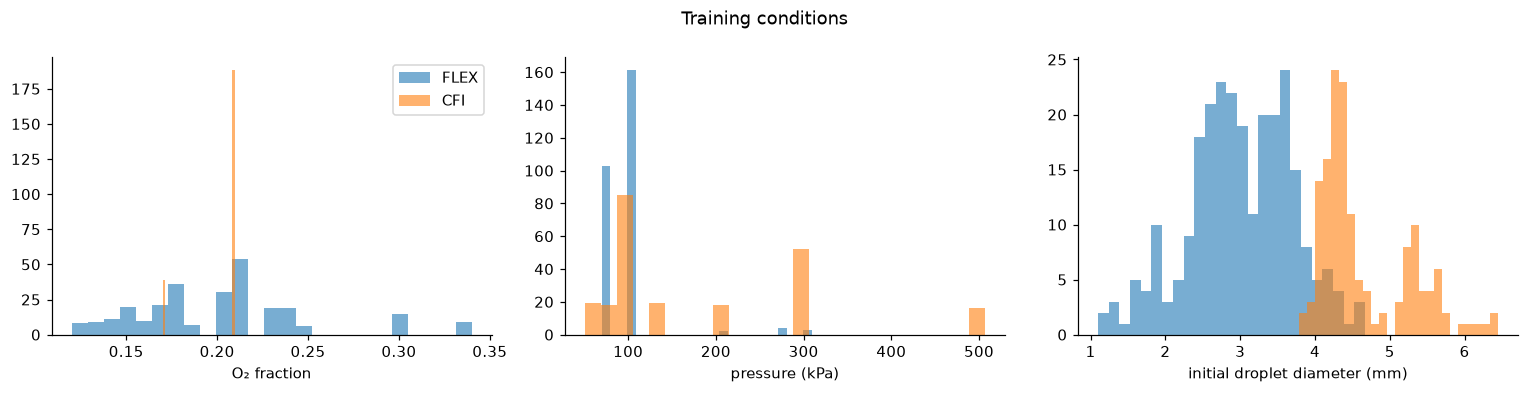

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for a, (c, lab) in zip(ax, [("o2_frac", "O₂ fraction"), ("pressure_kpa", "pressure (kPa)"), ("droplet_d0_mm", "initial droplet diameter (mm)")]):
    for acc, name in [("PSI-69", "FLEX"), ("PSI-39", "CFI")]:
        a.hist(drops.loc[drops.accession == acc, c].dropna(), bins=25, alpha=.6, label=name)
    a.set_xlabel(lab)
ax[0].legend(); fig.suptitle("Training conditions"); plt.tight_layout()

### 4.1 Regression models: burning rate *K* and extinction diameter

Validation = **GroupKFold by test campaign** (FLEX campaign prefix, CFI test month). Tests from the same campaign share hardware, fuel batch and crew, so a random split would leak and flatter the model.

Every model is compared with three alternatives: *gradient boosting*, *linear regression* and *predict the mean*. The GP earns its place only if it matches the best of them **and** gives honest uncertainty: its 95 % intervals should contain about 95 % of the held-out tests.

In [7]:
fitted, rows = {}, []
for name, target in {"burning_rate": "burning_rate_mm2_s", "extinction_d": "extinction_d_mm"}.items():
    model, met, n, k = tm.cv_regression(drops, target)
    fitted[name] = model
    for m, v in met.items():
        rows.append({"model": name, "method": m, "n": n, "folds": k, **v})
reg = pd.DataFrame(rows).set_index(["model", "method"]).round(3)
reg

n  folds    MAE     R2  95%_interval_coverage
model        method                                                   
burning_rate gp        405      5  0.084  0.601                  0.916
             boosting  405      5  0.091  0.589                    NaN
             linear    405      5  0.092  0.588                    NaN
             mean      405      5  0.152 -0.046                    NaN
extinction_d gp        340      5  0.311  0.912                  0.826
             boosting  340      5  0.409  0.852                    NaN
             linear    340      5  0.353  0.902                    NaN
             mean      340      5  1.600 -0.427                    NaN

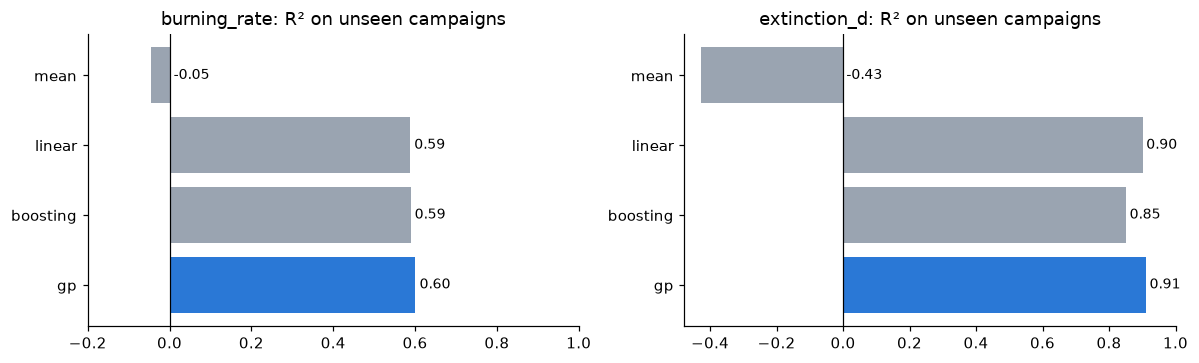

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for a, name in zip(ax, ["burning_rate", "extinction_d"]):
    r = reg.loc[name]["R2"]
    a.barh(r.index, r.values, color=["#2a78d6" if i == "gp" else "#9aa4b1" for i in r.index])
    a.axvline(0, color="k", lw=.8); a.set_title(f"{name}: R² on unseen campaigns"); a.set_xlim(min(-0.2, r.min() - .05), 1)
    for i, v in enumerate(r.values):
        a.text(max(v, 0) + .01, i, f"{v:.2f}", va="center", fontsize=9)
plt.tight_layout()

### 4.2 Classifiers: does the flame go out cleanly, and does a cool flame survive?

- **outcome** (FLEX): radiative/diffusive *extinction* vs droplet *disruption* (break-up)
- **cool_flame** (CFI): after the hot flame goes out, does a cool flame keep burning? That's a re-ignition hazard for suppression systems.

Compare the GP with logistic regression and with the *majority-class* accuracy (always guess the commonest answer). AUC is the fairer score when one class dominates.

In [9]:
rows = []
for label, name in [(None, "outcome (FLEX)"), ("cool_flame", "cool_flame (CFI)")]:
    model, met, n, k = tm.cv_outcome(drops, label)
    fitted[name] = model
    rows.append({"model": name, "n": n, "folds": k, "GP AUC": met["gp"]["AUC"], "GP accuracy": met["gp"]["accuracy"],
                 "logistic AUC": met["logistic"]["AUC"], "majority accuracy": met["majority_class_accuracy"]})
pd.DataFrame(rows).set_index("model").round(3)

,n,folds,GP AUC,GP accuracy,logistic AUC,majority accuracy
model,,,,,,
outcome (FLEX),234,5,0.827,0.774,0.813,0.765
cool_flame (CFI),145,5,0.767,0.828,0.728,0.855


### 4.3 What the GP learned: length-scales

An ARD kernel learns one length-scale per feature. A **short** length-scale means the prediction changes quickly with that feature (important). A **very long** one means the feature barely matters.

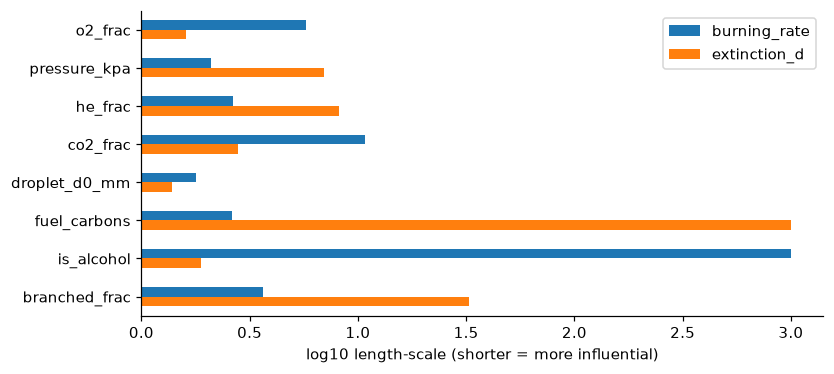

In [10]:
def lengthscales(pipe):
    k = pipe[-1].kernel_
    rbf = [p for p in k.get_params().values() if hasattr(p, "length_scale") and np.ndim(p.length_scale) == 1][0]
    return pd.Series(rbf.length_scale, index=tm.FEATURES)
ls = pd.DataFrame({n: lengthscales(fitted[n]) for n in ["burning_rate", "extinction_d"]})
ax = np.log10(ls).plot.barh(figsize=(8, 3.6)); ax.set_xlabel("log10 length-scale (shorter = more influential)"); ax.invert_yaxis()

### 4.4 Habitat predictions and the uncertainty map

Prediction for a 2 mm methanol droplet (FLEX-1 conditions) in each habitat atmosphere. The heat map shows the 95 % uncertainty over O₂ × pressure. Bright = the model is guessing = **where a new experiment would teach us most**.

In [11]:
hab = []
row = lambda o2, p: [o2 / 100, p, 0.0, 0.0, 2.0, 1.0, 1.0, 0.0]
for h, v in tm.HABITATS.items():
    mu, sd = fitted["burning_rate"].predict(np.array([row(v["o2_pct"], v["pressure_kpa"])]), return_std=True)
    hab.append({"habitat": h, "O2 %": v["o2_pct"], "pressure kPa": round(v["pressure_kpa"], 1), "K mean": mu[0], "K ±95%": 1.96 * sd[0]})
pd.DataFrame(hab).set_index("habitat").round(3)

,O2 %,pressure kPa,K mean,K ±95%
habitat,,,,
Earth sea level,20.9,101.3,0.538,0.136
ISS cabin,21.0,101.3,0.539,0.136
Moon base / rover (expected),34.0,70.3,0.681,0.193
Mars habitat (assumed = Moon),34.0,70.3,0.681,0.193
Spacesuit,100.0,29.6,0.453,0.848


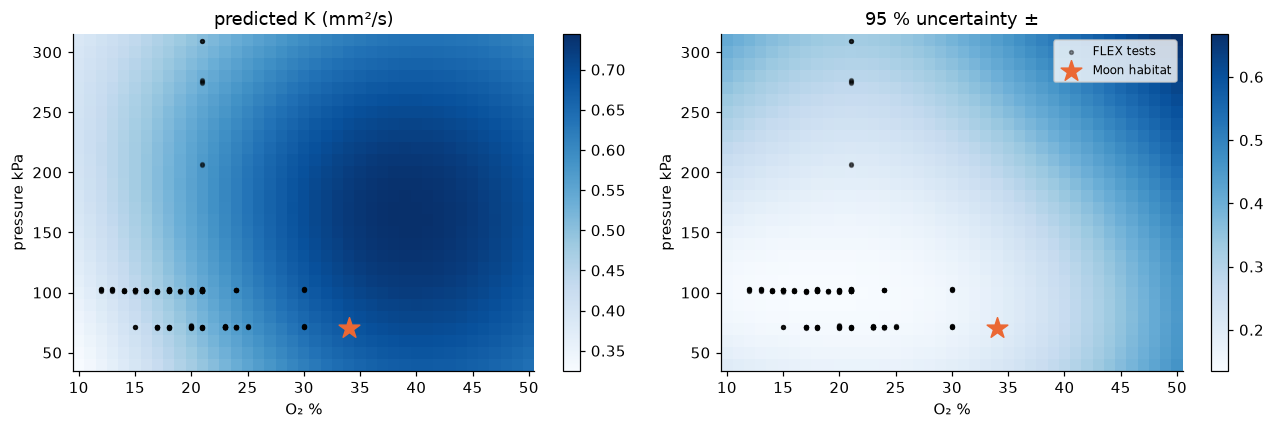

In [12]:
o2 = np.linspace(10, 50, 41); pk = np.linspace(40, 310, 28)
G = np.array([row(a, b) for b in pk for a in o2])
mu, sd = fitted["burning_rate"].predict(G, return_std=True)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, z, title in [(ax[0], mu, "predicted K (mm²/s)"), (ax[1], 1.96 * sd, "95 % uncertainty ±")]:
    im = a.pcolormesh(o2, pk, z.reshape(len(pk), len(o2)), cmap="Blues", shading="auto"); fig.colorbar(im, ax=a)
    f = drops[drops.accession == "PSI-69"]; a.scatter(f.o2_frac * 100, f.pressure_kpa, s=6, c="k", alpha=.4, label="FLEX tests")
    a.scatter([34], [70.3], marker="*", s=200, c="#eb6834", label="Moon habitat"); a.set_xlabel("O₂ %"); a.set_ylabel("pressure kPa"); a.set_title(title)
ax[1].legend(loc="upper right", fontsize=8); plt.tight_layout()

## 5. Prevention: will a solid keep burning? (BASS)

The labels come from the crew's *Test Observations* column in the BASS as-run matrix, turned into categories by simple, auditable rules (`label_bass` in `pipeline/build_tests.py`):
*no ignition* · *ignited, not self-sustaining* · *burned* (and whether nitrogen or reduced air flow put it out).

In [13]:
import build_tests as bt
bass = tests[tests.accession == "PSI-26"]
print(bass.outcome.value_counts().to_string()); print()
bass[["material", "o2_frac", "flow_cm_s", "outcome", "extinguished_by", "notes"]].sample(6, random_state=1)

outcome
burned                          98
ignited, not self-sustaining    10
unknown                          9
no ignition                      5



,material,o2_frac,flow_cm_s,outcome,extinguished_by,notes
965,candle,0.222199,5.0,burned,burnout,"same candle, no filter, changed iso. Burned t..."
1029,2 cm sphere,0.171300,10.0,unknown,NaN,broke 2 igniters. No ignition on this test....
990,"Japan Wax Candle, wake",0.212449,2.0,burned,low flow,A mode. Trying to heat and then step to low ...
1022,parrafin wax candle,0.160500,5.0,burned,low flow,ignited 'concurrent' or stagnation.17:45 - 0.5...
962,SIBAL 2 cm,0.222199,9.0,burned,burnout,"opposed flow flame test, steady spread at 9 c..."
948,1 cm sphere,0.208896,10.0,burned,low flow,"adjusted igniter, start at 60, ignite, fan to ..."


In [14]:
prev = tm.prevention(tests)
m = prev["metrics"]
pd.DataFrame({"GP": m["gp"], "logistic": m["logistic"]}).T.assign(majority_accuracy=m["majority_class_accuracy"], base_rate_brier=m["base_rate_brier"]).round(3)

,AUC,accuracy,brier,majority_accuracy,base_rate_brier
GP,0.918,0.912,0.062,0.863,0.118
logistic,0.886,0.892,NaN,0.863,0.118


,tests,sustained,model_p_burn_iss_air,did_not_sustain,lowest_o2_pct_that_burned,extinguished_by_low_flow,flow_at_low_flow_extinction_cm_s,extinguished_by_n2
material,,,,,,,,
Nomex (aramid fabric),6,1,0.2,5,22.0,0,NaN,0
PMMA (acrylic),63,58,1.0,5,17.1,29,1.0,2
SIBAL (cotton/fiberglass),12,12,0.9,0,21.5,1,5.8,0
other,2,0,0.2,2,NaN,0,NaN,0
wax,19,17,0.9,2,15.9,8,0.0,0


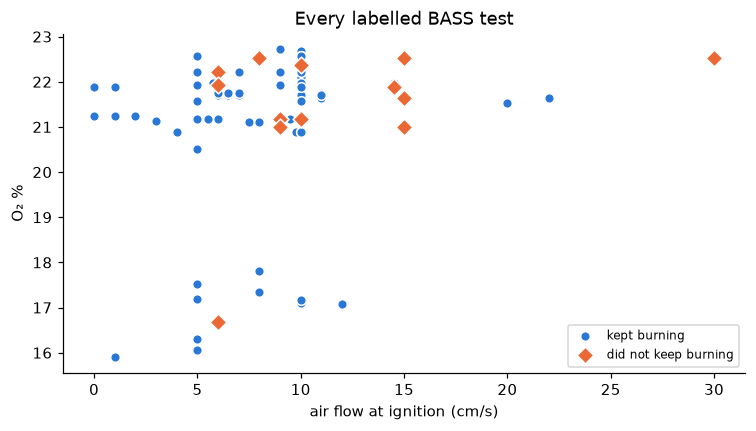

In [15]:
pts = pd.DataFrame(prev["points"])
fig, ax = plt.subplots(figsize=(8, 4))
for burned, col, mk, lab in [(True, "#2a78d6", "o", "kept burning"), (False, "#eb6834", "D", "did not keep burning")]:
    q = pts[pts.burned == burned]; ax.scatter(q.flow_cm_s, q.o2_pct, c=col, marker=mk, s=40 if burned else 60, edgecolor="white", label=lab)
ax.set_xlabel("air flow at ignition (cm/s)"); ax.set_ylabel("O₂ %"); ax.set_title("Every labelled BASS test"); ax.legend(fontsize=8)
pd.DataFrame(prev["materials"]).set_index("material").round(1)

> **Honest reading:** only ~13 of ~100 labelled tests failed to keep burning, all near 21 % O₂ and 1 atm. The classifier ranks risk better than chance (AUC), but its probabilities don't yet beat the base rate (Brier). The Prevention layer's biggest need is **more non-burning tests and tests at Moon/Mars atmospheres**, and the dashboard says so.

## 6. Detection: smoke (SAME, SAME-R, SPICE)

Each SAME/SAME-R run heated a cabin material, aged the smoke, and pushed it past five detectors plus particle counters. Per run we keep:
- the **baseline** (before the heater switched on) and the **smoke window** (after it switched off)
- each detector's robust peak response, and whether it rose above 10× baseline noise (*responded*)
- smoke mass (DustTrak), particle count (P-Trak) and a mass/number **particle-size index**

In [16]:
cols = [c for c in det.columns if c.endswith("_responded")]
det.groupby("material")[["dusttrak_peak_mg_m3", "ptrak_peak_per_cc", "mean_diameter_index_um"]].median().round(2).join(
    det.groupby("material")[cols].agg(lambda s: s.dropna().astype(float).mean()).round(2))

,dusttrak_peak_mg_m3,ptrak_peak_per_cc,mean_diameter_index_um,iss_obscuration_responded,iss_scatter_responded,ion_a_responded,ion_b_responded,sts_responded,n_detectors_responded
material,,,,,,,,,
Dibutyl phthalate,31.42,2627.0,2.89,0.90,0.90,0.29,0.62,0.00,2.71
Kapton,8.81,44250.0,0.71,0.38,0.86,0.38,0.90,0.29,2.62
Lampwick (cotton),42.17,48500.0,1.21,0.94,0.94,0.65,0.94,0.20,3.53
Pyrell (PU foam),88.56,56296.0,1.68,0.93,0.93,0.71,0.79,0.33,3.43
Silicone rubber,107.30,57572.0,1.73,0.96,0.96,0.79,0.92,0.38,3.75
Teflon,6.14,49100.0,0.74,0.37,0.89,0.47,0.79,0.17,2.58


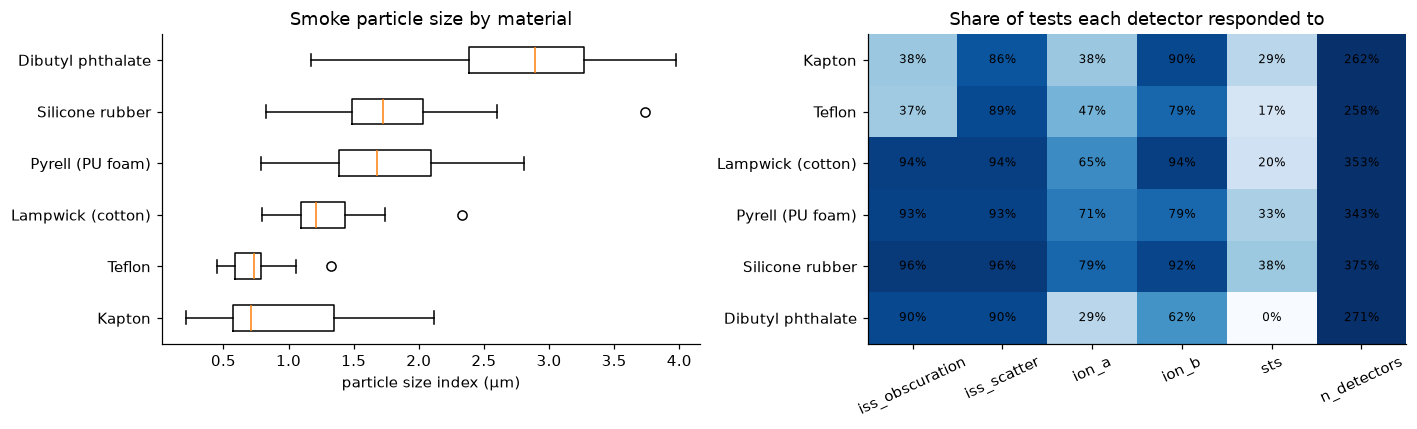

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
order = det.groupby("material").mean_diameter_index_um.median().sort_values().index
ax[0].boxplot([det.loc[det.material == m, "mean_diameter_index_um"].dropna() for m in order], tick_labels=order, vert=False)
ax[0].set_xlabel("particle size index (µm)"); ax[0].set_title("Smoke particle size by material")
rate = det.groupby("material")[cols].agg(lambda s: s.dropna().astype(float).mean()).loc[order].astype(float)
im = ax[1].imshow(rate.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax[1].set_yticks(range(len(order)), order); ax[1].set_xticks(range(len(cols)), [c.replace("_responded", "") for c in cols], rotation=25)
for i in range(rate.shape[0]):
    for j in range(rate.shape[1]):
        v = rate.values[i, j]; ax[1].text(j, i, "–" if np.isnan(v) else f"{v:.0%}", ha="center", va="center", fontsize=8)
ax[1].set_title("Share of tests each detector responded to"); plt.tight_layout()

Teflon and Kapton make the **smallest** particles, and the ISS photoelectric *obscuration* channel responds to far fewer of those tests. That's the SAME finding: some cabin materials make smoke that current detector designs struggle to see.

In [18]:
detl = tm.detection()
pd.DataFrame({k: detl[k]["metrics"]["gp"] | {"n": detl[k]["n"]} for k in ["smoke_mass_model", "smoke_point_model"]}).T.round(3)

,MAE,R2,95%_interval_coverage,n
smoke_mass_model,0.336,0.569,0.928,69.0
smoke_point_model,9.303,0.556,0.743,70.0


In [19]:
rows = []
for k in ["smoke_mass_model", "smoke_point_model"]:
    for meth, v in detl[k]["metrics"].items():
        rows.append({"model": k, "method": meth, **v})
pd.DataFrame(rows).set_index(["model", "method"]).round(3)

MAE     R2  95%_interval_coverage
model             method                                        
smoke_mass_model  gp         0.336  0.569                  0.928
                  boosting   0.371  0.469                    NaN
                  linear     0.296  0.582                    NaN
                  mean       0.586 -0.030                    NaN
smoke_point_model gp         9.303  0.556                  0.743
                  boosting  12.688  0.165                    NaN
                  linear     9.664  0.571                    NaN
                  mean      16.614 -0.081                    NaN

Text(0.5, 0, 'smoke-point flame length (mm), shorter = sootier')

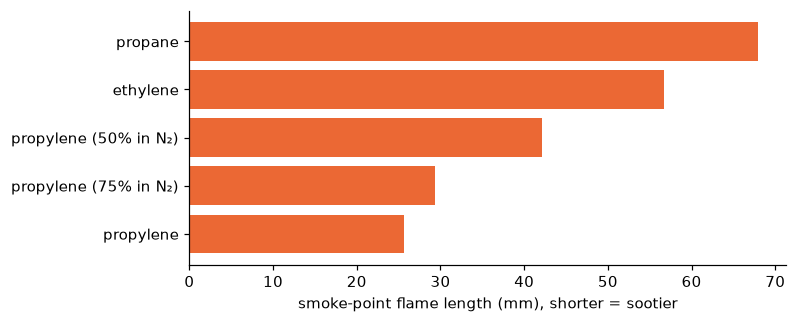

In [20]:
spt = pd.DataFrame(detl["smoke_points"]).sort_values("median")
lab = spt.fuel + np.where(spt.fuel_mole_frac < 1, " (" + (spt.fuel_mole_frac * 100).round().astype(int).astype(str) + "% in N₂)", "")
ax = plt.figure(figsize=(7, 3)).gca(); ax.barh(lab, spt["median"], color="#eb6834"); ax.set_xlabel("smoke-point flame length (mm), shorter = sootier")

## 7. Save models and dashboard data

Runs `pipeline/train_models.py` end to end. They write:
- `data/processed/models/*.joblib`: fitted models
- `data/processed/model_report.json`, `layers_report.json`: metrics for the write-up
- `dashboard/public/data/model.json`, `layers.json`: what the dashboard shows (*Predictions* and *Fire-safety layers* pages)

In [21]:
if SAVE_OUTPUTS:
    tm.main()   # suppression models -> model.json, then prevention/detection -> layers.json
else:
    print("SAVE_OUTPUTS is False - nothing written")

burning_rate   n=405  GP MAE=0.084 R2=0.60 cov95=0.92 | boosting R2=0.59 | linear R2=0.59 | mean R2=-0.05


extinction_d   n=340  GP MAE=0.311 R2=0.91 cov95=0.83 | boosting R2=0.85 | linear R2=0.90 | mean R2=-0.43


outcome        n=234  GP AUC=0.8271203656678517 acc=0.77 | logistic AUC=0.8126968004062975 | majority=0.76


cool_flame     n=145  GP AUC=0.7665130568356374 acc=0.83 | logistic AUC=0.728110599078341 | majority=0.86



Habitat predictions (burning-rate K, mm^2/s):
  Earth sea level                  K=0.538 ± 0.136  in-range=True
  ISS cabin                        K=0.539 ± 0.136  in-range=True
  Moon base / rover (expected)     K=0.681 ± 0.193  in-range=True
  Mars habitat (assumed = Moon)    K=0.681 ± 0.193  in-range=True
  Spacesuit                        K=0.453 ± 0.848  in-range=False

Tests near each habitat atmosphere (±5% O2, ±25% P):
  Earth sea level                   579  {'BASS': 121, 'BASS-II': 114, 'FLEX': 110, 'CFI': 85, 'ACME Flame Design': 71, 'ACME CFI-G': 35, 'FLEX-2': 24, 'ACME s-Flame': 10, 'SAFFIRE-II': 7, 'SAFFIRE-I': 2}
  ISS cabin                         576  {'BASS': 120, 'BASS-II': 112, 'FLEX': 110, 'CFI': 85, 'ACME Flame Design': 71, 'ACME CFI-G': 35, 'FLEX-2': 24, 'ACME s-Flame': 10, 'SAFFIRE-II': 7, 'SAFFIRE-I': 2}
  Moon base / rover (expected)       17  {'FLEX': 17}
  Mars habitat (assumed = Moon)      17  {'FLEX': 17}
  Spacesuit                           0  {}



PREVENTION  P(sustained burn) n=102 (pos 88)  GP AUC=0.92 brier=0.062 (base 0.118) | logistic AUC=0.89
DETECTION   smoke mass n=69  GP R2=0.57 MAE=0.34 dex | boosting R2=0.47 | linear R2=0.58
DETECTION   smoke point n=70  GP R2=0.56 MAE=9.3 mm cov95=0.74 | boosting R2=0.17 | linear R2=0.57
materials (prevention):
   {'material': 'Nomex (aramid fabric)', 'tests': 6, 'sustained': 1, 'model_p_burn_iss_air': 0.18406090813448373, 'did_not_sustain': 5, 'lowest_o2_pct_that_burned': 21.983426531024726, 'extinguished_by_low_flow': 0, 'flow_at_low_flow_extinction_cm_s': None, 'extinguished_by_n2': 0}
   {'material': 'PMMA (acrylic)', 'tests': 63, 'sustained': 58, 'model_p_burn_iss_air': 0.9839647485856631, 'did_not_sustain': 5, 'lowest_o2_pct_that_burned': 17.07, 'extinguished_by_low_flow': 29, 'flow_at_low_flow_extinction_cm_s': 1.0, 'extinguished_by_n2': 2}
   {'material': 'SIBAL (cotton/fiberglass)', 'tests': 12, 'sustained': 12, 'model_p_burn_iss_air': 0.9288925046668055, 'did_not_sustain': 

## 8. Scorecard

In [22]:
rep = json.loads((P / "model_report.json").read_text()); lay = json.loads((P / "layers_report.json").read_text())
card = []
for k, v in rep["models"].items():
    g = v["metrics"]["gp"]
    card.append({"layer": "Suppression", "model": k, "n": v["n"], "score": g.get("R2", g.get("AUC")), "metric": "R²" if "R2" in g else "AUC"})
card.append({"layer": "Prevention", "model": "sustained_burn", "n": lay["prevention"]["n"], "score": lay["prevention"]["metrics"]["gp"]["AUC"], "metric": "AUC"})
for k in ["smoke_mass_model", "smoke_point_model"]:
    card.append({"layer": "Detection", "model": k, "n": lay["detection"][k]["n"], "score": lay["detection"][k]["metrics"]["gp"]["R2"], "metric": "R²"})
pd.DataFrame(card).round(3)

,layer,model,n,score,metric
0,Suppression,burning_rate,405,0.601,R²
1,Suppression,extinction_d,340,0.912,R²
2,Suppression,outcome,234,0.827,AUC
3,Suppression,cool_flame,145,0.767,AUC
4,Prevention,sustained_burn,102,0.918,AUC
5,Detection,smoke_mass_model,69,0.569,R²
6,Detection,smoke_point_model,70,0.556,R²
